# 04 · Pandas  ⏱️ ~35 min

**Pandas** = la bibliothèque pour manipuler des **tableaux de données** (comme Excel, mais en code).

Deux objets à connaître :
- **`Series`** : une colonne (valeurs + un index)
- **`DataFrame`** : un tableau = plusieurs Series qui partagent le même index (lignes) ; chaque colonne a un nom

On va travailler sur `data/ventes.csv` (30 ventes fictives).

In [ ]:
import pandas as pd
import numpy as np

## 1. Series

In [ ]:
s = pd.Series([12, 7, 15], index=["Alice", "Bob", "Chloé"], name="notes")
print(s)
print(s["Bob"])        # accès par étiquette d'index
print(s.mean(), s.max())
print(s[s > 10])       # filtrage booléen, comme numpy

Alice    12
Bob       7
Chloé    15
Name: notes, dtype: int64
7
11.333333333333334 15
Alice    12
Chloé    15
Name: notes, dtype: int64


## 2. Créer un DataFrame
Le plus courant : depuis un **dictionnaire** `{nom_colonne: liste_de_valeurs}`.

In [ ]:
df_mini = pd.DataFrame({
    "nom":   ["Alice", "Bob", "Chloé"],
    "age":   [25, 32, 28],
    "ville": ["Paris", "Lyon", "Paris"],
})
df_mini

,nom,age,ville
0,Alice,25,Paris
1,Bob,32,Lyon
2,Chloé,28,Paris


## 3. Lire / écrire des fichiers
```python
pd.read_csv("fichier.csv")                  # sep=";" pour un CSV "à la française"
pd.read_excel("fichier.xlsx", sheet_name=0) # nécessite openpyxl
df.to_csv("sortie.csv", index=False)
df.to_excel("sortie.xlsx", index=False)
```

In [ ]:
df = pd.read_csv("data/ventes.csv", parse_dates=["date"])   # parse_dates : convertit la colonne en vraies dates
df.head()        # 5 premières lignes (df.head(10) pour 10)

,date,vendeur,region,produit,quantite,prix_unitaire
0,2025-01-09,David,Est,Écran,9.0,180.0
1,2025-01-14,Emma,Sud,Clavier,3.0,25.0
2,2025-01-16,Alice,Nord,Casque,6.0,60.0
3,2025-01-16,Emma,Sud,Écran,1.0,180.0
4,2025-01-18,Chloé,Nord,Clavier,NaN,25.0


## 4. Explorer un DataFrame — les premiers réflexes

In [ ]:
print(df.shape)          # (nb lignes, nb colonnes)
print(df.columns.tolist())
df.tail(3)               # 3 dernières lignes

(30, 6)
['date', 'vendeur', 'region', 'produit', 'quantite', 'prix_unitaire']


,date,vendeur,region,produit,quantite,prix_unitaire
27,2025-03-31,Alice,Nord,Écran,10.0,180.0
28,2025-04-02,Chloé,Nord,Souris,10.0,15.0
29,2025-04-05,David,Est,Souris,5.0,15.0


In [ ]:
df.info()                # types de colonnes + valeurs non nulles -> repérer les manquants

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           30 non-null     datetime64[us]
 1   vendeur        30 non-null     str           
 2   region         29 non-null     str           
 3   produit        30 non-null     str           
 4   quantite       28 non-null     float64       
 5   prix_unitaire  30 non-null     float64       
dtypes: datetime64[us](1), float64(2), str(3)
memory usage: 1.5 KB


In [ ]:
df.describe()            # statistiques des colonnes numériques

,date,quantite,prix_unitaire
count,30,28.000000,30.000000
mean,2025-02-20 22:24:00,6.000000,75.500000
min,2025-01-09 00:00:00,1.000000,15.000000
25%,2025-02-01 06:00:00,3.000000,15.000000
50%,2025-02-19 00:00:00,6.000000,42.500000
75%,2025-03-16 06:00:00,9.250000,180.000000
max,2025-04-05 00:00:00,11.000000,180.000000
std,NaN,3.288589,71.430579


In [ ]:
print(df["produit"].unique())          # valeurs distinctes
print(df["produit"].nunique())         # nombre de valeurs distinctes
df["vendeur"].value_counts()           # fréquence de chaque valeur ⭐

<StringArray>
['Écran', 'Clavier', 'Casque', 'Souris']
Length: 4, dtype: str
4


vendeur
Chloé    9
Emma     8
David    7
Alice    4
Bob      2
Name: count, dtype: int64

## 5. Sélectionner des colonnes

In [ ]:
df["produit"]                      # une colonne -> Series (simples crochets)

0       Écran
1     Clavier
2      Casque
3       Écran
4     Clavier
5      Souris
6     Clavier
7      Souris
8      Souris
9       Écran
10     Souris
11     Casque
12     Casque
13      Écran
14     Souris
15    Clavier
16      Écran
17      Écran
18     Souris
19     Casque
20    Clavier
21      Écran
22     Casque
23     Souris
24     Casque
25    Clavier
26      Écran
27      Écran
28     Souris
29     Souris
Name: produit, dtype: str

In [ ]:
df[["vendeur", "produit", "quantite"]].head()   # plusieurs colonnes -> DataFrame (DOUBLES crochets)

,vendeur,produit,quantite
0,David,Écran,9.0
1,Emma,Clavier,3.0
2,Alice,Casque,6.0
3,Emma,Écran,1.0
4,Chloé,Clavier,NaN


## 6. Sélectionner des lignes : `loc` vs `iloc` ⭐

| | `loc` | `iloc` |
|---|---|---|
| basé sur | les **étiquettes** (noms d'index / de colonnes) | les **positions** (0, 1, 2…) |
| slice `a:b` | `b` **inclus** | `b` **exclu** |
| syntaxe | `df.loc[lignes, colonnes]` | `df.iloc[lignes, colonnes]` |

In [ ]:
df.iloc[0]               # première ligne (Series)

date             2025-01-09 00:00:00
vendeur                        David
region                           Est
produit                        Écran
quantite                         9.0
prix_unitaire                  180.0
Name: 0, dtype: object

In [ ]:
df.iloc[0:3, 0:2]        # lignes 0,1,2 / colonnes 0,1 (positions, fin exclue)

,date,vendeur
0,2025-01-09,David
1,2025-01-14,Emma
2,2025-01-16,Alice


In [ ]:
df.loc[0:3, ["vendeur", "quantite"]]   # index 0 à 3 INCLUS, colonnes par nom

,vendeur,quantite
0,David,9.0
1,Emma,3.0
2,Alice,6.0
3,Emma,1.0


In [ ]:
print(df.loc[5, "produit"])            # une cellule précise
print(df.iloc[-1, -1])                 # dernière cellule

Souris
15.0


## 7. Filtrer (sélection conditionnelle) ⭐⭐
Exactement comme numpy : condition → masque booléen → `df[masque]`.

In [ ]:
df[df["region"] == "Nord"]

,date,vendeur,region,produit,quantite,prix_unitaire
2,2025-01-16,Alice,Nord,Casque,6.0,60.0
4,2025-01-18,Chloé,Nord,Clavier,NaN,25.0
5,2025-01-26,Chloé,Nord,Souris,2.0,15.0
6,2025-01-28,Chloé,Nord,Clavier,6.0,25.0
7,2025-01-31,Alice,Nord,Souris,10.0,15.0
16,2025-02-27,Chloé,Nord,Écran,7.0,180.0
20,2025-03-06,Alice,Nord,Clavier,5.0,25.0
22,2025-03-19,Chloé,Nord,Casque,9.0,60.0
24,2025-03-22,Chloé,Nord,Casque,3.0,60.0
25,2025-03-23,Chloé,Nord,Clavier,2.0,25.0


In [ ]:
# Plusieurs conditions : & (et), | (ou), ~ (non) et des PARENTHÈSES autour de chaque condition
df[(df["produit"] == "Écran") & (df["quantite"] >= 5)]

,date,vendeur,region,produit,quantite,prix_unitaire
0,2025-01-09,David,Est,Écran,9.0,180.0
9,2025-02-05,David,Est,Écran,11.0,180.0
13,2025-02-14,Emma,Sud,Écran,6.0,180.0
16,2025-02-27,Chloé,Nord,Écran,7.0,180.0
21,2025-03-08,Emma,Sud,Écran,10.0,180.0
27,2025-03-31,Alice,Nord,Écran,10.0,180.0


In [ ]:
df[df["vendeur"].isin(["Alice", "Bob"])].head()      # appartient à une liste

,date,vendeur,region,produit,quantite,prix_unitaire
2,2025-01-16,Alice,Nord,Casque,6.0,60.0
7,2025-01-31,Alice,Nord,Souris,10.0,15.0
10,2025-02-09,Bob,Sud,Souris,3.0,15.0
12,2025-02-11,Bob,Sud,Casque,5.0,60.0
20,2025-03-06,Alice,Nord,Clavier,5.0,25.0


In [ ]:
df.query("prix_unitaire > 50 and region == 'Sud'")   # alternative lisible à écrire en texte

,date,vendeur,region,produit,quantite,prix_unitaire
3,2025-01-16,Emma,Sud,Écran,1.0,180.0
12,2025-02-11,Bob,Sud,Casque,5.0,60.0
13,2025-02-14,Emma,Sud,Écran,6.0,180.0
21,2025-03-08,Emma,Sud,Écran,10.0,180.0
26,2025-03-26,Emma,Sud,Écran,3.0,180.0


In [ ]:
# Filtrer ET choisir les colonnes en même temps avec loc
df.loc[df["quantite"] > 9, ["date", "vendeur", "quantite"]]

,date,vendeur,quantite
7,2025-01-31,Alice,10.0
9,2025-02-05,David,11.0
15,2025-02-19,Emma,10.0
21,2025-03-08,Emma,10.0
23,2025-03-19,Emma,11.0
27,2025-03-31,Alice,10.0
28,2025-04-02,Chloé,10.0


In [ ]:
# Filtres sur du texte et des dates
print(df[df["produit"].str.startswith("C")]["produit"].unique())
df[df["date"] >= "2025-03-01"].head(3)

<StringArray>
['Clavier', 'Casque']
Length: 2, dtype: str


,date,vendeur,region,produit,quantite,prix_unitaire
17,2025-03-02,David,Est,Écran,NaN,180.0
18,2025-03-04,David,Est,Souris,7.0,15.0
19,2025-03-06,David,Est,Casque,2.0,60.0


## 8. Valeurs manquantes (NaN)

In [ ]:
df.isna().sum()          # nombre de manquants par colonne

date             0
vendeur          0
region           1
produit          0
quantite         2
prix_unitaire    0
dtype: int64

In [ ]:
df[df["quantite"].isna()]             # voir les lignes concernées

,date,vendeur,region,produit,quantite,prix_unitaire
4,2025-01-18,Chloé,Nord,Clavier,NaN,25.0
17,2025-03-02,David,Est,Écran,NaN,180.0


In [ ]:
df_sans_na = df.dropna()                                  # supprime les lignes avec au moins un NaN
print(len(df), "->", len(df_sans_na))

df["quantite"] = df["quantite"].fillna(0)                 # remplace les NaN par 0
df["region"] = df["region"].fillna("Inconnue")
df.isna().sum()

30 -> 27


date             0
vendeur          0
region           0
produit          0
quantite         0
prix_unitaire    0
dtype: int64

## 9. Créer / modifier / supprimer des colonnes

In [ ]:
df["ca"] = df["quantite"] * df["prix_unitaire"]               # calcul vectorisé
df["mois"] = df["date"].dt.month                              # .dt pour les dates
df["gros_achat"] = df["ca"] > 500                             # colonne booléenne
df["taille"] = np.where(df["ca"] > 500, "gros", "petit")      # if/else vectorisé
df["vendeur_maj"] = df["vendeur"].str.upper()                 # .str pour le texte
df.head()

,date,vendeur,region,produit,quantite,prix_unitaire,ca,mois,gros_achat,taille,vendeur_maj
0,2025-01-09,David,Est,Écran,9.0,180.0,1620.0,1,True,gros,DAVID
1,2025-01-14,Emma,Sud,Clavier,3.0,25.0,75.0,1,False,petit,EMMA
2,2025-01-16,Alice,Nord,Casque,6.0,60.0,360.0,1,False,petit,ALICE
3,2025-01-16,Emma,Sud,Écran,1.0,180.0,180.0,1,False,petit,EMMA
4,2025-01-18,Chloé,Nord,Clavier,0.0,25.0,0.0,1,False,petit,CHLOÉ


In [ ]:
# apply : appliquer une fonction à chaque valeur (plus lent que le vectorisé, mais flexible)
def categorie_prix(prix):
    if prix < 20:
        return "éco"
    elif prix < 100:
        return "standard"
    return "premium"

df["gamme"] = df["prix_unitaire"].apply(categorie_prix)
df["initiale"] = df["vendeur"].apply(lambda v: v[0])

# Supprimer et renommer
df = df.drop(columns=["vendeur_maj", "initiale"])
df = df.rename(columns={"prix_unitaire": "prix"})

# Changer un type
df["quantite"] = df["quantite"].astype(int)
df.head()

,date,vendeur,region,produit,quantite,prix,ca,mois,gros_achat,taille,gamme
0,2025-01-09,David,Est,Écran,9,180.0,1620.0,1,True,gros,premium
1,2025-01-14,Emma,Sud,Clavier,3,25.0,75.0,1,False,petit,standard
2,2025-01-16,Alice,Nord,Casque,6,60.0,360.0,1,False,petit,standard
3,2025-01-16,Emma,Sud,Écran,1,180.0,180.0,1,False,petit,premium
4,2025-01-18,Chloé,Nord,Clavier,0,25.0,0.0,1,False,petit,standard


## 10. Trier

In [ ]:
df.sort_values("ca", ascending=False).head()          # du plus grand au plus petit

,date,vendeur,region,produit,quantite,prix,ca,mois,gros_achat,taille,gamme
9,2025-02-05,David,Est,Écran,11,180.0,1980.0,2,True,gros,premium
21,2025-03-08,Emma,Sud,Écran,10,180.0,1800.0,3,True,gros,premium
27,2025-03-31,Alice,Nord,Écran,10,180.0,1800.0,3,True,gros,premium
0,2025-01-09,David,Est,Écran,9,180.0,1620.0,1,True,gros,premium
16,2025-02-27,Chloé,Nord,Écran,7,180.0,1260.0,2,True,gros,premium


In [ ]:
df.sort_values(["vendeur", "date"]).head()            # tri sur plusieurs colonnes

,date,vendeur,region,produit,quantite,prix,ca,mois,gros_achat,taille,gamme
2,2025-01-16,Alice,Nord,Casque,6,60.0,360.0,1,False,petit,standard
7,2025-01-31,Alice,Nord,Souris,10,15.0,150.0,1,False,petit,éco
20,2025-03-06,Alice,Nord,Clavier,5,25.0,125.0,3,False,petit,standard
27,2025-03-31,Alice,Nord,Écran,10,180.0,1800.0,3,True,gros,premium
10,2025-02-09,Bob,Sud,Souris,3,15.0,45.0,2,False,petit,éco


In [ ]:
df.nlargest(3, "ca")[["vendeur", "produit", "ca"]]     # top 3

,vendeur,produit,ca
9,David,Écran,1980.0
21,Emma,Écran,1800.0
27,Alice,Écran,1800.0


## 11. Agréger : `groupby` ⭐⭐
Logique **split → apply → combine** : on découpe par groupe, on calcule, on rassemble. Équivalent du « tableau croisé dynamique » d'Excel.

In [ ]:
df.groupby("vendeur")["ca"].sum()                     # CA total par vendeur

vendeur
Alice    2435.0
Bob       345.0
Chloé    2780.0
David    3915.0
Emma     4150.0
Name: ca, dtype: float64

In [ ]:
df.groupby("vendeur")["ca"].sum().sort_values(ascending=False)

vendeur
Emma     4150.0
David    3915.0
Chloé    2780.0
Alice    2435.0
Bob       345.0
Name: ca, dtype: float64

In [ ]:
# Plusieurs statistiques d'un coup
df.groupby("produit")["quantite"].agg(["sum", "mean", "count"])

,sum,mean,count
produit,,,
Casque,32,5.333333,6
Clavier,26,4.333333,6
Souris,53,5.888889,9
Écran,57,6.333333,9


In [ ]:
# Agrégation nommée (résultat propre) + reset_index pour retrouver un DataFrame "plat"
resume = (
    df.groupby(["region", "produit"])
      .agg(ca_total=("ca", "sum"), nb_ventes=("ca", "count"), qte_moy=("quantite", "mean"))
      .reset_index()
)
resume.head(8)

,region,produit,ca_total,nb_ventes,qte_moy
0,Est,Casque,120.0,1,2.000000
1,Est,Souris,195.0,3,4.333333
2,Est,Écran,3600.0,3,6.666667
3,Inconnue,Casque,420.0,1,7.000000
4,Nord,Casque,1080.0,3,6.000000
5,Nord,Clavier,325.0,4,3.250000
6,Nord,Souris,330.0,3,7.333333
7,Nord,Écran,3060.0,2,8.500000


In [ ]:
# Tableau croisé dynamique
pd.pivot_table(df, values="ca", index="vendeur", columns="produit", aggfunc="sum", fill_value=0)

produit,Casque,Clavier,Souris,Écran
vendeur,,,,
Alice,360.0,125.0,150.0,1800.0
Bob,300.0,0.0,45.0,0.0
Chloé,1140.0,200.0,180.0,1260.0
David,120.0,0.0,195.0,3600.0
Emma,0.0,325.0,225.0,3600.0


## 12. Combiner des DataFrames : `merge` et `concat`
`merge` = la **RECHERCHEV / jointure SQL** de pandas.

In [ ]:
vendeurs = pd.read_csv("data/vendeurs.csv")
vendeurs

,vendeur,anciennete_ans,objectif_ca
0,Alice,5,3000
1,Bob,2,2500
2,Chloé,8,4000
3,David,1,2000
4,Emma,3,2500


In [ ]:
ca_vendeur = df.groupby("vendeur", as_index=False)["ca"].sum()
bilan = pd.merge(ca_vendeur, vendeurs, on="vendeur", how="left")   # how : left, right, inner, outer
bilan["objectif_atteint"] = bilan["ca"] >= bilan["objectif_ca"]
bilan

,vendeur,ca,anciennete_ans,objectif_ca,objectif_atteint
0,Alice,2435.0,5,3000,False
1,Bob,345.0,2,2500,False
2,Chloé,2780.0,8,4000,False
3,David,3915.0,1,2000,True
4,Emma,4150.0,3,2500,True


In [ ]:
# concat : empiler des tableaux qui ont les mêmes colonnes
janvier = df[df["mois"] == 1]
fevrier = df[df["mois"] == 2]
pd.concat([janvier, fevrier], ignore_index=True).shape

(17, 11)

## 13. Index, doublons, dates

In [ ]:
print(df.duplicated().sum(), "doublon(s)")
df = df.drop_duplicates()

df_idx = df.set_index("date")                 # mettre une colonne en index
ca_mensuel = df_idx["ca"].resample("MS").sum()   # agrégation temporelle (MS = début de mois)
ca_mensuel

0 doublon(s)


date
2025-01-01    2565.0
2025-02-01    5410.0
2025-03-01    5425.0
2025-04-01     225.0
Freq: MS, Name: ca, dtype: float64

## 14. Un graphique rapide
Pandas a une méthode `.plot()` (basée sur matplotlib).

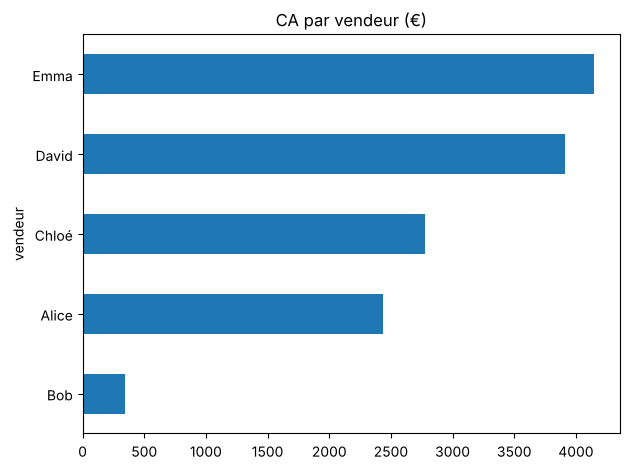

In [ ]:
import matplotlib.pyplot as plt

df.groupby("vendeur")["ca"].sum().sort_values().plot(kind="barh", title="CA par vendeur (€)")
plt.tight_layout()
plt.show()

## 15. Enregistrer le résultat

In [ ]:
bilan.to_csv("data/bilan_vendeurs.csv", index=False)
print("Fichier écrit ✅")

Fichier écrit ✅


## 🧭 Le workflow type d'une analyse
1. `pd.read_csv` → charger
2. `head / info / describe / value_counts / isna().sum()` → explorer
3. `dropna / fillna / astype / rename / drop_duplicates` → nettoyer
4. nouvelles colonnes, `np.where`, `apply` → enrichir
5. filtres, `loc`, `groupby`, `pivot_table`, `merge` → analyser
6. `.plot()` / `to_csv` → restituer

## ✍️ Mini-exercices (réponses dans `05_exercices.ipynb`)
1. Combien de ventes contiennent un « Casque » ?
2. Quel est le CA total de la région Sud ?
3. Quel produit a généré le plus de CA ?
4. Affiche les ventes de Chloé triées par date, colonnes `date`, `produit`, `ca`.
5. Ajoute une colonne `remise` = 10 % du CA si le CA dépasse 1000 €, sinon 0.
6. Quel est le CA moyen par vente pour chaque mois ?

In [ ]:
# À toi de jouer 👇